Se uso BERT con 3000 reseñas

# Descripcipción del proyecto

Film Junky Union, una nueva comunidad vanguardista para los aficionados de las películas clásicas, está desarrollando un sistema para filtrar y categorizar reseñas de películas. Tu objetivo es entrenar un modelo para detectar las críticas negativas de forma automática. Para lograrlo, utilizarás un conjunto de datos de reseñas de películas de IMDB con leyendas de polaridad para construir un modelo para clasificar las reseñas positivas y negativas. Este deberá alcanzar un valor F1 de al menos 0.85.

## Inicialización

In [51]:
import re
import math

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from tqdm.auto import tqdm

In [52]:
print(plt.style.available)

['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6', 'petroff8', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


In [53]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
# la siguiente línea proporciona gráficos de mejor calidad en pantallas HiDPI
%config InlineBackend.figure_format = 'retina'

# plt.style.use('seaborn')
plt.style.use('seaborn-v0_8')

In [54]:
# esto es para usar progress_apply, puedes leer más en https://pypi.org/project/tqdm/#pandas-integration
tqdm.pandas()

## Cargar datos

In [55]:
df_reviews = pd.read_csv('datasets/imdb_reviews.tsv', sep='\t', dtype={'votes': 'Int64'})

In [56]:
# Mostrar información del DataFrame
df_reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 47331 entries, 0 to 47330
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   tconst           47331 non-null  str    
 1   title_type       47331 non-null  str    
 2   primary_title    47331 non-null  str    
 3   original_title   47331 non-null  str    
 4   start_year       47331 non-null  int64  
 5   end_year         47331 non-null  str    
 6   runtime_minutes  47331 non-null  str    
 7   is_adult         47331 non-null  int64  
 8   genres           47331 non-null  str    
 9   average_rating   47329 non-null  float64
 10  votes            47329 non-null  Int64  
 11  review           47331 non-null  str    
 12  rating           47331 non-null  int64  
 13  sp               47331 non-null  str    
 14  pos              47331 non-null  int64  
 15  ds_part          47331 non-null  str    
 16  idx              47331 non-null  int64  
dtypes: Int64(1), float64(1)

Los que se requeriran en el proyecto:

- review: el texto de la reseña
- pos: el objetivo, '0' para negativo y '1' para positivo
- ds_part: 'entrenamiento'/'prueba' para la parte de entrenamiento/prueba del conjunto de datos, respectivamente

In [57]:
# Imprimir una muestra de los datos
df_reviews.sample(10)

,tconst,title_type,primary_title,original_title,start_year,end_year,runtime_minutes,is_adult,genres,average_rating,votes,review,rating,sp,pos,ds_part,idx
27032,tt0926129,movie,Prom Night,Prom Night,2008,\N,88,0,"Horror,Mystery",3.9,33121,Okay. So I just got back. Before I start my re...,1,neg,0,train,661
23182,tt0264935,movie,Murder by Numbers,Murder by Numbers,2002,\N,115,0,"Crime,Mystery,Thriller",6.2,51925,"At first the movie seemed to be doing great, t...",2,neg,0,test,1538
9782,tt0437152,tvMovie,Descent,Descent,2005,\N,90,0,"Action,Drama,Sci-Fi",3.3,819,Terry Cunningham directs this Sci-Fi Network o...,3,neg,0,test,2733
37188,tt0119196,movie,The Gingerbread Man,The Gingerbread Man,1998,\N,114,0,"Crime,Mystery,Thriller",5.7,10348,I have seen some bad movies (Austin Powers - T...,1,neg,0,train,1070
46488,tt0043137,movie,Winchester '73,Winchester '73,1950,\N,92,0,"Action,Drama,Western",7.6,16158,"By 1955, five years after this one was release...",8,pos,1,train,6931
5895,tt0995060,movie,Brutal Massacre: A Comedy,Brutal Massacre: A Comedy,2007,\N,94,0,Comedy,6.1,690,I saw this movie a few days ago... what the he...,3,neg,0,train,5779
42500,tt0201290,movie,The Underground Comedy Movie,The Underground Comedy Movie,1999,\N,88,0,Comedy,2.2,2417,"Hawked as THE MOST OFFENSIVE MOVIE EVER, GUARA...",1,neg,0,train,11002
10904,tt0312640,video,Dragon Fighter,Dragon Fighter,2003,\N,85,0,"Action,Sci-Fi,Thriller",3.4,1071,"This is a formula B science fiction movie, and...",3,neg,0,train,9018
11976,tt0101829,movie,Europa,Europa,1991,\N,112,0,"Drama,Thriller",7.6,19241,This is the movie for those who believe cinema...,10,pos,1,train,109
28044,tt0089893,movie,Red Sonja,Red Sonja,1985,\N,89,0,"Action,Adventure,Fantasy",5.1,37733,Recap: Since the warrior queen Gedren raised a...,2,neg,0,test,5723


In [58]:
# Estadísticas del DataFrame
df_reviews.describe()

,start_year,is_adult,average_rating,votes,rating,pos,idx
count,47331.000000,47331.000000,47329.000000,47329.0,47331.000000,47331.000000,47331.000000
mean,1989.631235,0.001732,5.998278,25562.917323,5.484608,0.498954,6279.697999
std,19.600364,0.041587,1.494289,83670.039163,3.473109,0.500004,3605.702545
min,1894.000000,0.000000,1.400000,9.0,1.000000,0.000000,0.000000
25%,1982.000000,0.000000,5.100000,827.0,2.000000,0.000000,3162.000000
50%,1998.000000,0.000000,6.300000,3197.0,4.000000,0.000000,6299.000000
75%,2004.000000,0.000000,7.100000,13974.0,9.000000,1.000000,9412.000000
max,2010.000000,1.000000,9.700000,1739448.0,10.000000,1.000000,12499.000000


## EDA

Veamos el número de películas y reseñas a lo largo de los años.

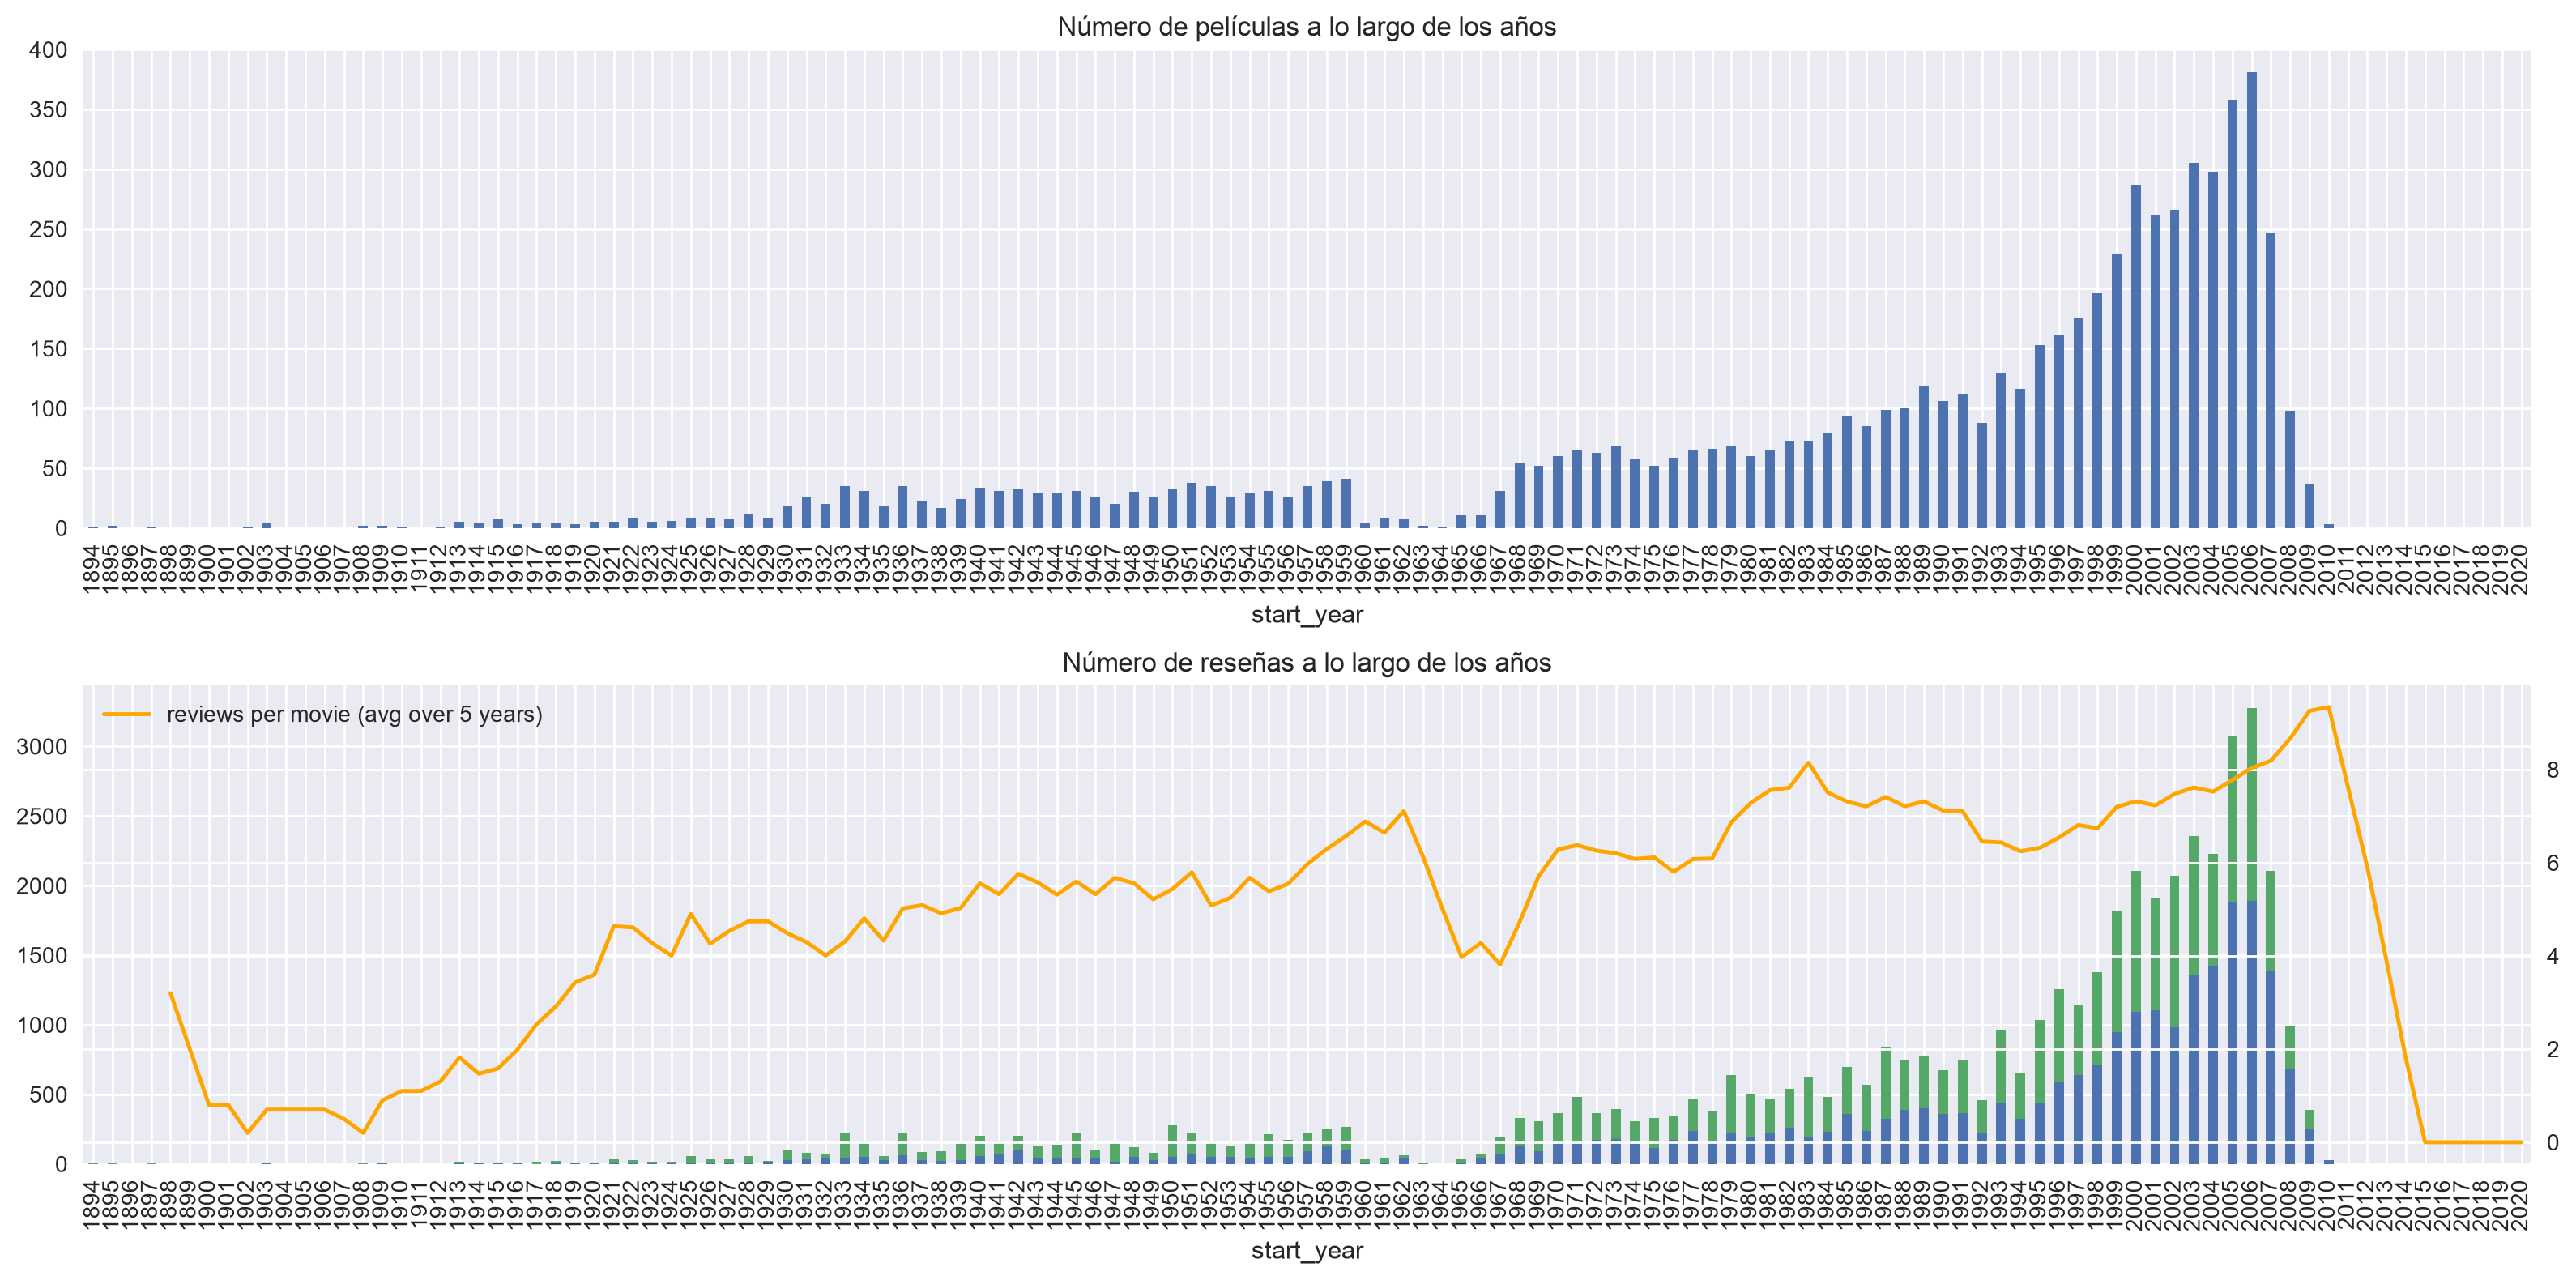

In [59]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8))

ax = axs[0]

dft1 = df_reviews[['tconst', 'start_year']].drop_duplicates() \
    ['start_year'].value_counts().sort_index()
dft1 = dft1.reindex(index=np.arange(dft1.index.min(), max(dft1.index.max(), 2021))).fillna(0)
dft1.plot(kind='bar', ax=ax)
ax.set_title('Número de películas a lo largo de los años')

ax = axs[1]

dft2 = df_reviews.groupby(['start_year', 'pos'])['pos'].count().unstack()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)

dft2.plot(kind='bar', stacked=True, label='#reviews (neg, pos)', ax=ax)

dft2 = df_reviews['start_year'].value_counts().sort_index()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)
dft3 = (dft2/dft1).fillna(0)
axt = ax.twinx()
dft3.reset_index(drop=True).rolling(5).mean().plot(color='orange', label='reviews per movie (avg over 5 years)', ax=axt)

lines, labels = axt.get_legend_handles_labels()
ax.legend(lines, labels, loc='upper left')

ax.set_title('Número de reseñas a lo largo de los años')

fig.tight_layout()

Veamos la distribución del número de reseñas por película con el conteo exacto y KDE (solo para saber cómo puede diferir del conteo exacto)

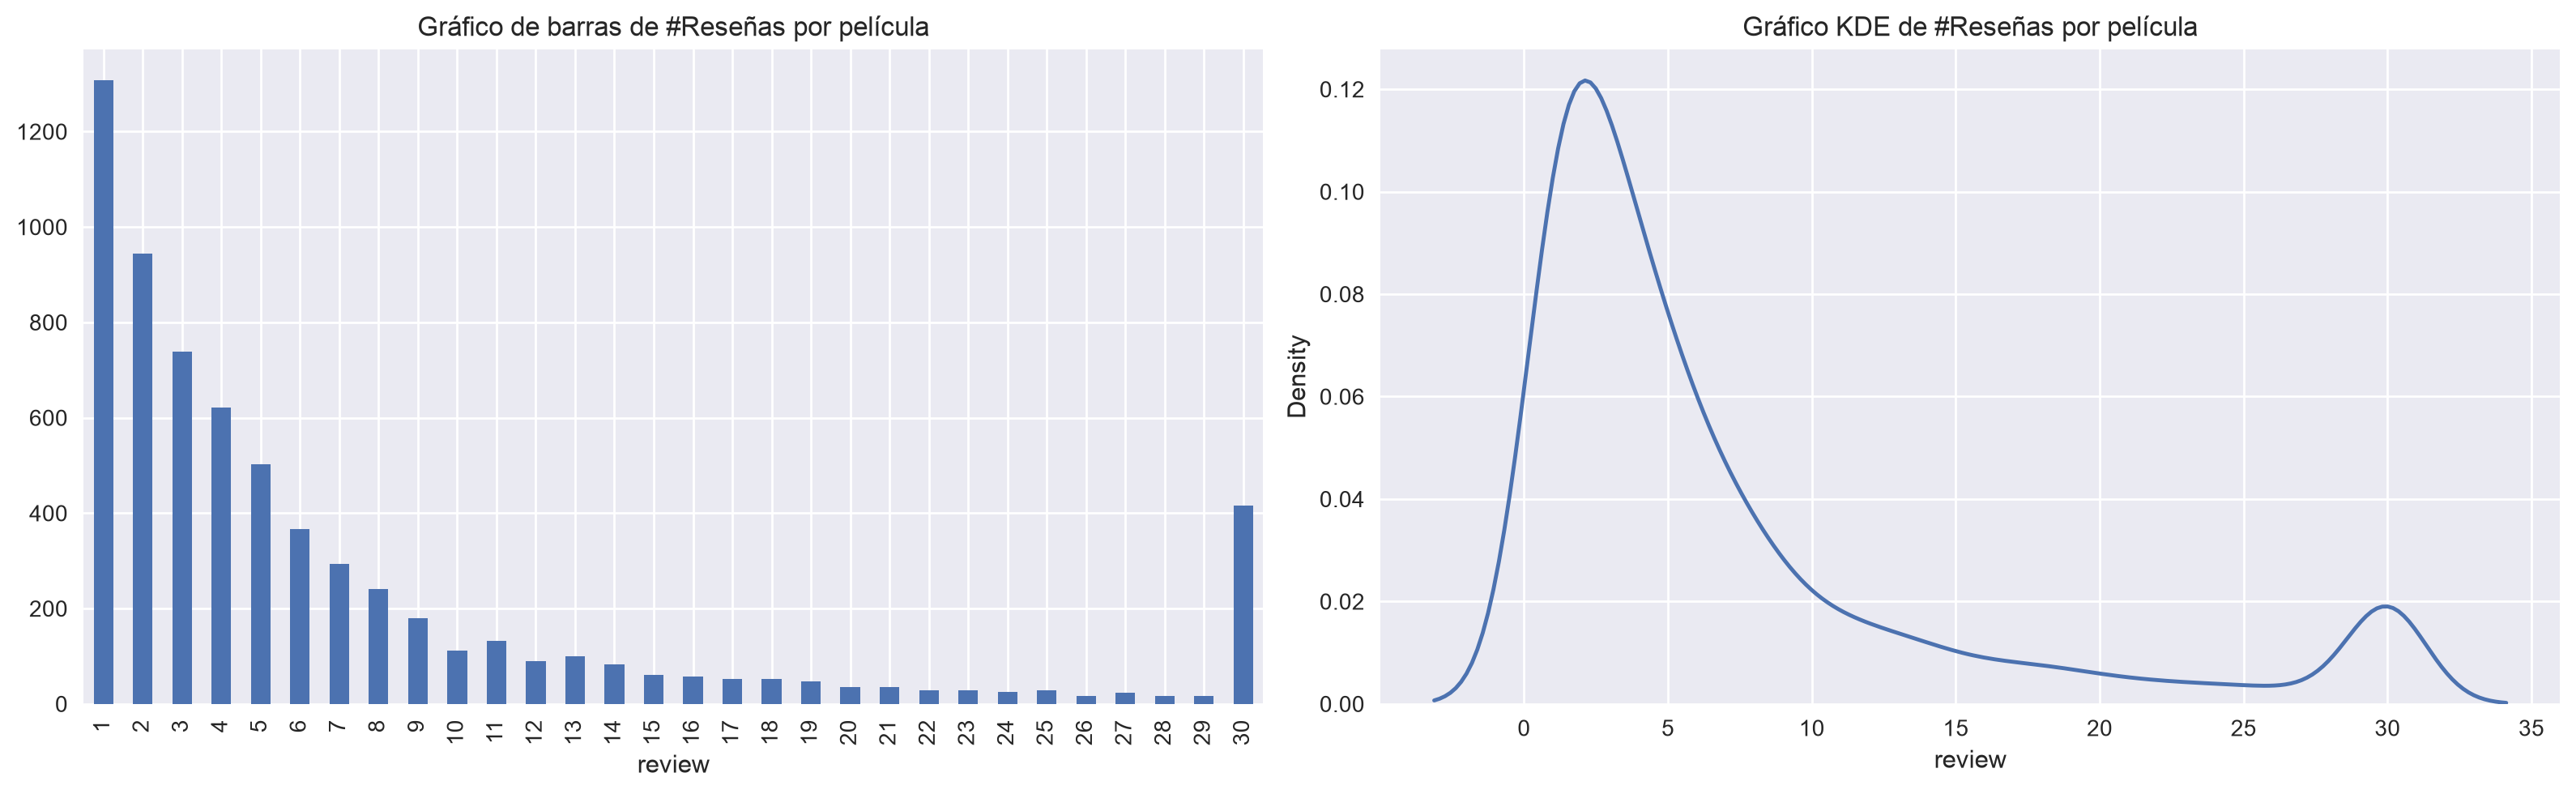

In [60]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5))

ax = axs[0]
dft = df_reviews.groupby('tconst')['review'].count() \
    .value_counts() \
    .sort_index()
dft.plot.bar(ax=ax)
ax.set_title('Gráfico de barras de #Reseñas por película')

ax = axs[1]
dft = df_reviews.groupby('tconst')['review'].count()
sns.kdeplot(dft, ax=ax)
ax.set_title('Gráfico KDE de #Reseñas por película')

fig.tight_layout()

In [61]:
df_reviews['pos'].value_counts()

pos
0    23715
1    23616
Name: count, dtype: int64

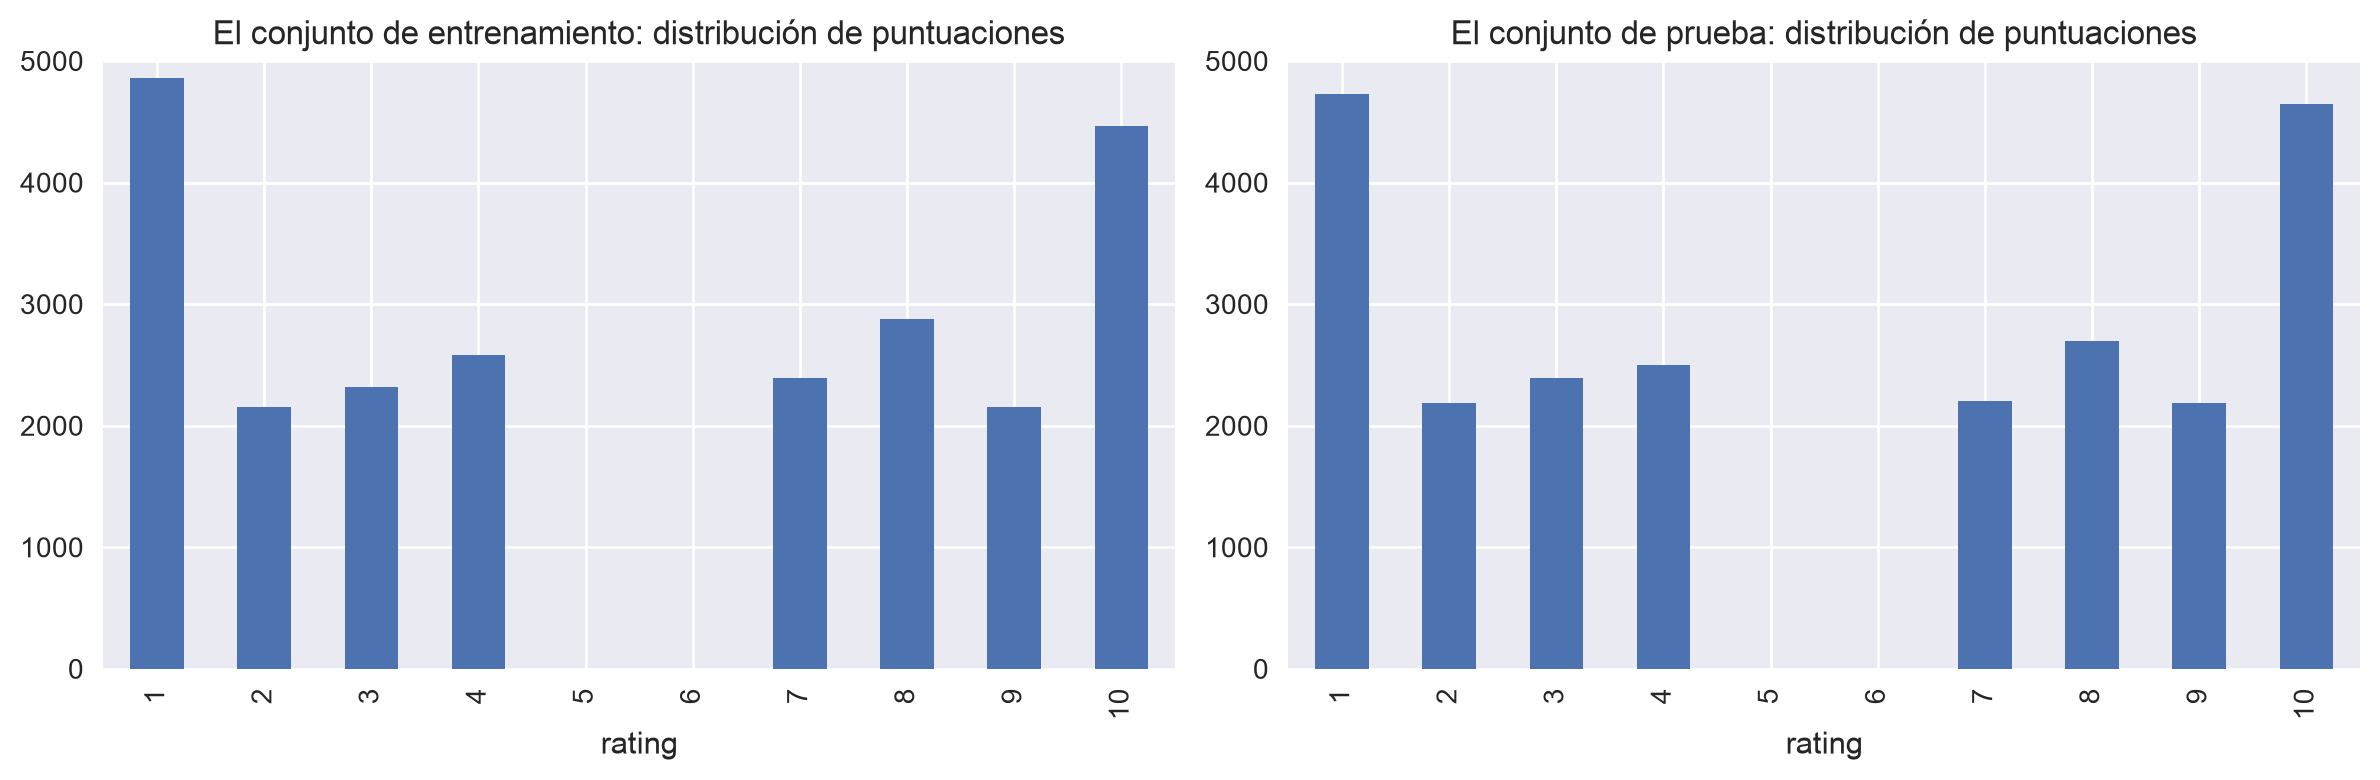

In [62]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

ax = axs[0]
dft = df_reviews.query('ds_part == "train"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('El conjunto de entrenamiento: distribución de puntuaciones')

ax = axs[1]
dft = df_reviews.query('ds_part == "test"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('El conjunto de prueba: distribución de puntuaciones')

fig.tight_layout()

Distribución de reseñas negativas y positivas a lo largo de los años para dos partes del conjunto de datos

/var/folders/4t/54sh_8mn0fq819mg255zxq7h0000gn/T/ipykernel_89474/1324160450.py:14: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
/var/folders/4t/54sh_8mn0fq819mg255zxq7h0000gn/T/ipykernel_89474/1324160450.py:15: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
/var/folders/4t/54sh_8mn0fq819mg255zxq7h0000gn/T/ipykernel_89474/1324160450.py:30: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
/var/folders/4t/54sh_8mn0fq819mg255zxq7h0000gn/T/ip

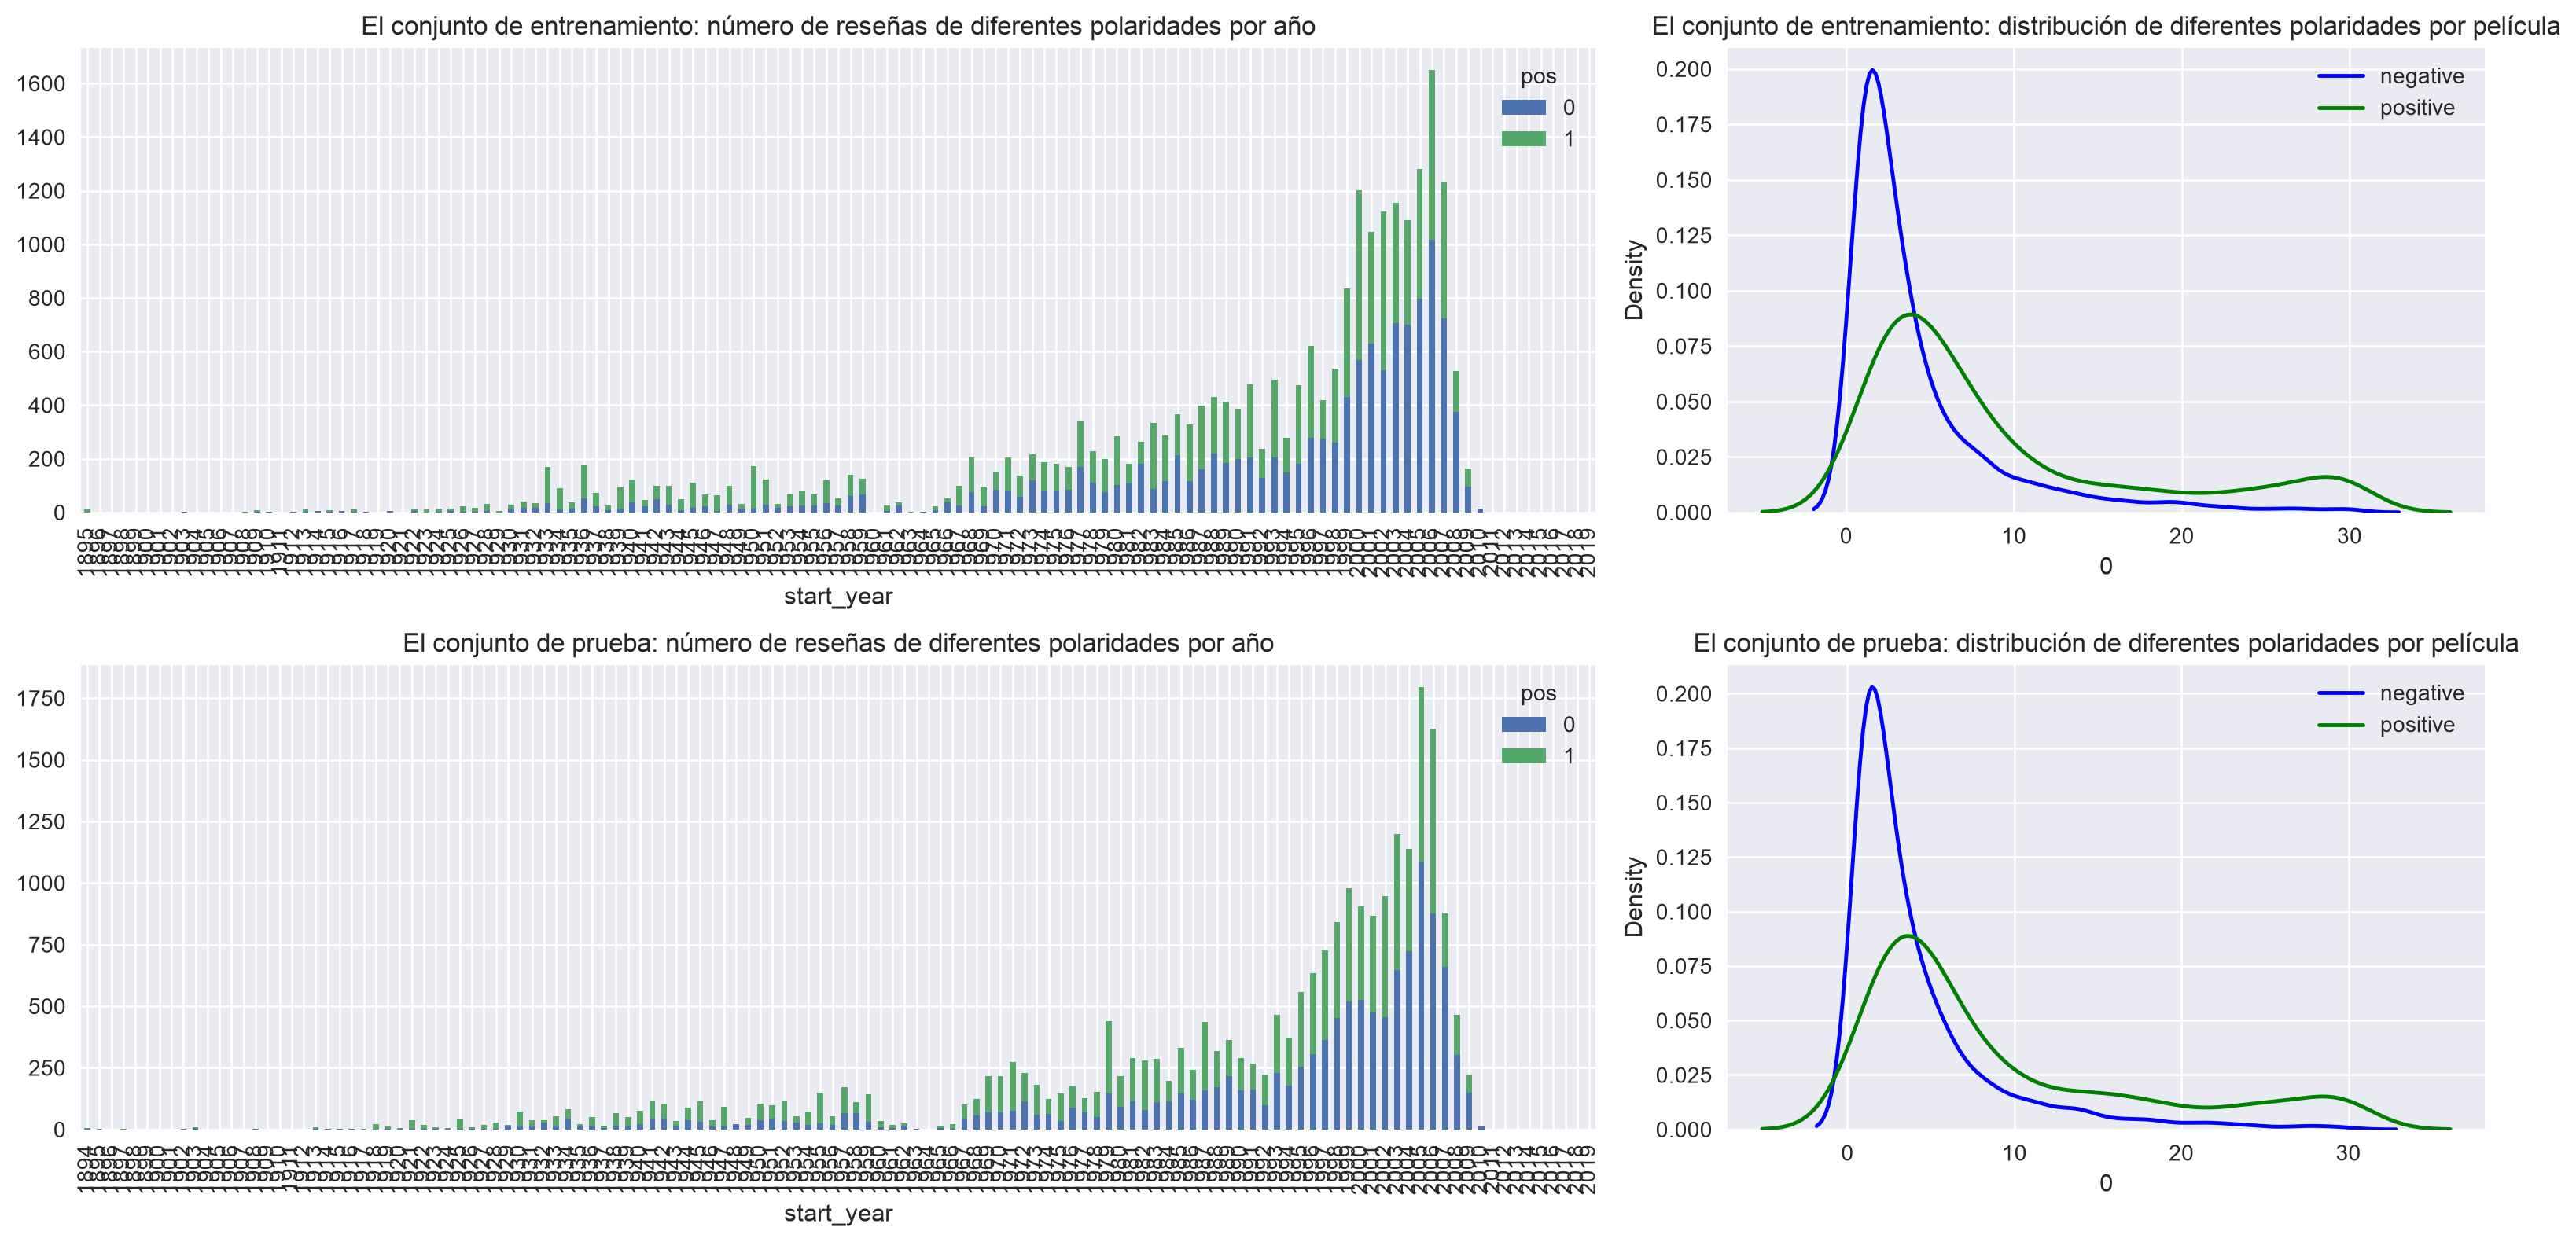

In [63]:
fig, axs = plt.subplots(2, 2, figsize=(16, 8), gridspec_kw=dict(width_ratios=(2, 1), height_ratios=(1, 1)))

ax = axs[0][0]

dft = df_reviews.query('ds_part == "train"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('El conjunto de entrenamiento: número de reseñas de diferentes polaridades por año')

ax = axs[0][1]

dft = df_reviews.query('ds_part == "train"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('El conjunto de entrenamiento: distribución de diferentes polaridades por película')

ax = axs[1][0]

dft = df_reviews.query('ds_part == "test"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('El conjunto de prueba: número de reseñas de diferentes polaridades por año')

ax = axs[1][1]

dft = df_reviews.query('ds_part == "test"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('El conjunto de prueba: distribución de diferentes polaridades por película')

fig.tight_layout()

## Procedimiento de evaluación

Composición de una rutina de evaluación que se pueda usar para todos los modelos en este proyecto

In [64]:
import sklearn.metrics as metrics
def evaluate_model(model, train_features, train_target, test_features, test_target):

    eval_stats = {}

    fig, axs = plt.subplots(1, 3, figsize=(20, 6))

    for type, features, target in (('train', train_features, train_target), ('test', test_features, test_target)):

        eval_stats[type] = {}

        pred_target = model.predict(features)
        pred_proba = model.predict_proba(features)[:, 1]

        # F1
        f1_thresholds = np.arange(0, 1.01, 0.05)
        f1_scores = [metrics.f1_score(target, pred_proba>=threshold) for threshold in f1_thresholds]

        # ROC
        fpr, tpr, roc_thresholds = metrics.roc_curve(target, pred_proba)
        roc_auc = metrics.roc_auc_score(target, pred_proba)
        eval_stats[type]['ROC AUC'] = roc_auc

        # PRC
        precision, recall, pr_thresholds = metrics.precision_recall_curve(target, pred_proba)
        aps = metrics.average_precision_score(target, pred_proba)
        eval_stats[type]['APS'] = aps

        if type == 'train':
            color = 'blue'
        else:
            color = 'green'

        # Valor F1
        ax = axs[0]
        max_f1_score_idx = np.argmax(f1_scores)
        ax.plot(f1_thresholds, f1_scores, color=color, label=f'{type}, max={f1_scores[max_f1_score_idx]:.2f} @ {f1_thresholds[max_f1_score_idx]:.2f}')
        # establecer cruces para algunos umbrales
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(f1_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(f1_thresholds[closest_value_idx], f1_scores[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('threshold')
        ax.set_ylabel('F1')
        ax.legend(loc='lower center')
        ax.set_title(f'Valor F1')

        # ROC
        ax = axs[1]
        ax.plot(fpr, tpr, color=color, label=f'{type}, ROC AUC={roc_auc:.2f}')
        # establecer cruces para algunos umbrales
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(roc_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(fpr[closest_value_idx], tpr[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.plot([0, 1], [0, 1], color='grey', linestyle='--')
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('FPR')
        ax.set_ylabel('TPR')
        ax.legend(loc='lower center')
        ax.set_title(f'Curva ROC')

        # PRC
        ax = axs[2]
        ax.plot(recall, precision, color=color, label=f'{type}, AP={aps:.2f}')
        # establecer cruces para algunos umbrales
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(pr_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(recall[closest_value_idx], precision[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('recall')
        ax.set_ylabel('precision')
        ax.legend(loc='lower center')
        ax.set_title(f'PRC')

        eval_stats[type]['Accuracy'] = metrics.accuracy_score(target, pred_target)
        eval_stats[type]['F1'] = metrics.f1_score(target, pred_target)

    df_eval_stats = pd.DataFrame(eval_stats)
    df_eval_stats = df_eval_stats.round(2)
    df_eval_stats = df_eval_stats.reindex(index=('Accuracy', 'F1', 'APS', 'ROC AUC'))

    print(df_eval_stats)

    return

## Normalización

Suponemos que todos los modelos a continuación aceptan textos en minúsculas y sin dígitos, signos de puntuación, etc.

In [65]:
# Función para normalizar las reseñas
def normalize_reviews(review):
    # patrón
    pattern = r'[^a-zA-Z]'
    review_without_digits = re.sub(pattern, ' ', review)
    review_split = review_without_digits.split()
    return " ".join(review_split)
    

In [66]:
df_reviews['review_norm'] = df_reviews['review'].apply(normalize_reviews)

df_reviews['review_norm'].head(10)

0    The pakage implies that Warren Beatty and Gold...
1    How the hell did they get this made Presenting...
2    There is no real story the film seems more lik...
3    Um a serious film about troubled teens in Sing...
4    I m totally agree with GarryJohal from Singapo...
5    This is the first movie I ve seen from Singapo...
6    Yes non Singaporean s can t see what s the big...
7    This true story of Carlson s Raiders is more o...
8    Should have been titled Balderdash Little in t...
9    The movie Gung Ho The Story of Carlson s Makin...
Name: review_norm, dtype: str

Se creo una función para normalizar el texto y con la ayuda del método apply se aplico a cada una de las filas.

## División entrenamiento / prueba

Por fortuna, todo el conjunto de datos ya está dividido en partes de entrenamiento/prueba; 'ds_part' es el indicador correspondiente.

In [67]:
df_reviews_train = df_reviews.query('ds_part == "train"').copy()
df_reviews_test = df_reviews.query('ds_part == "test"').copy()

train_target = df_reviews_train['pos']
test_target = df_reviews_test['pos']

print(df_reviews_train.shape)
print(df_reviews_test.shape)

(23796, 18)
(23535, 18)


## Trabajar con modelos

### Modelo 0 - Constante

In [68]:
from sklearn.dummy import DummyClassifier

In [69]:
# Corpus para el entrenamiento
train_corpus = df_reviews_train['review_norm']

# Corpus para el entrenamiento
test_corpus = df_reviews_test['review_norm']

In [70]:
# Inicialización y entrenamiento del modelo
model = DummyClassifier(strategy='uniform').fit(train_corpus, train_target)

          train  test
Accuracy    0.5  0.49
F1          0.5  0.49
APS         0.5  0.50
ROC AUC     0.5  0.50


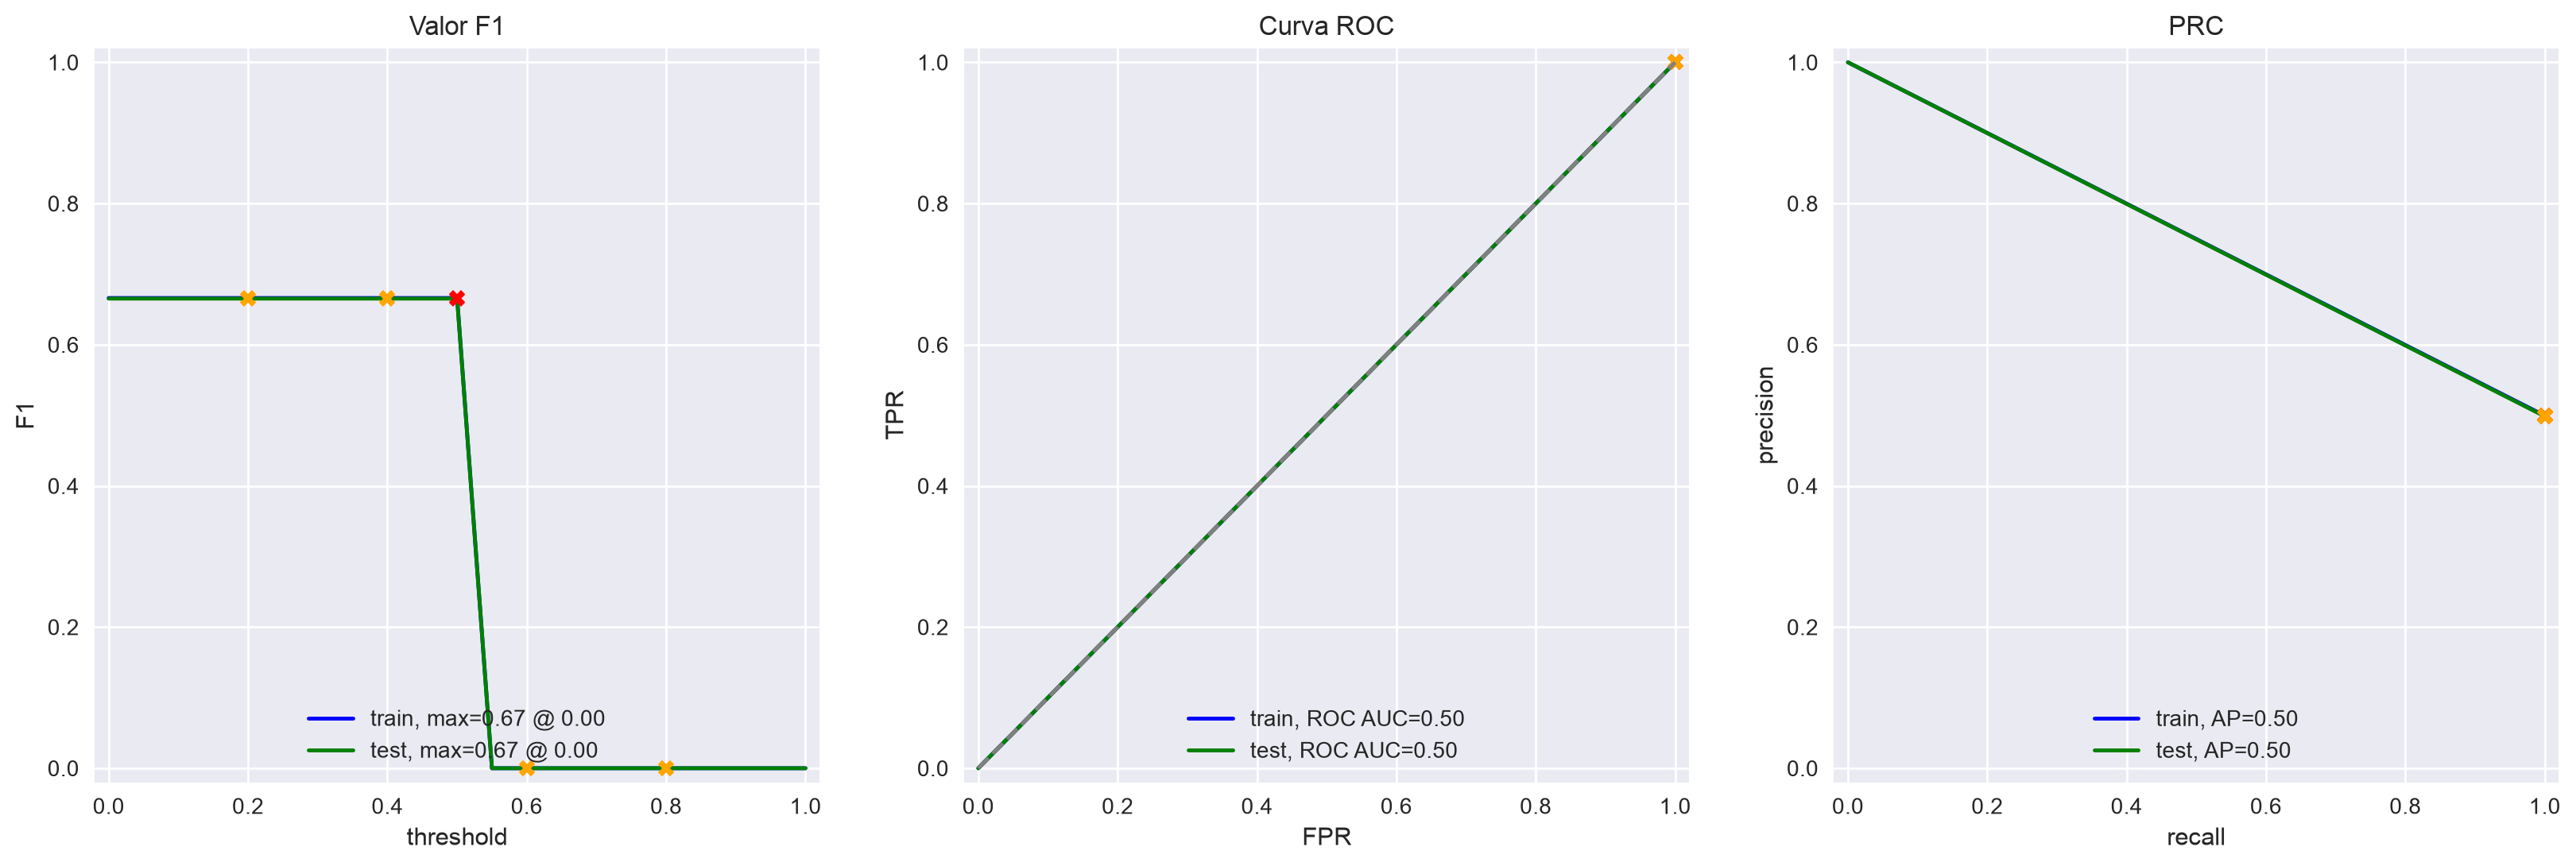

In [71]:
# Evaluación del modelo
evaluate_model(model, train_corpus, train_target, test_corpus, test_target)

**Valor F1:**

La gráfica muestra que de el umbral 0 a 0.5 el valor f1 se mantiene en 0.67, pero a partir de 0.5 a aproxidamente 0.55 el valor comienza a descender, finalmente apartir de 0.55 el f1 se mantiene en 0.

**Curva ROC:**

La curva ROC compara la tasa de verdaderos positivos (TPR) frente a la tasa de falsos positivos (FPR). 

En la gráfica se puede observar que tanto para el conjunto de entrenamiento como el conjunto de prueba obtuvieron un ROC AUC de 0.50. Claramente es el azar puro y el modelo no aporta nada.

**Curva PR:**

La curva Precision-Recall muestra el compromiso entre precisión y recall, siendo especialmente útil cuando existen clases desbalanceadas.

En este caso, se puede ver que tanto el conjunto de entrenamiento como el de prueba el umbral con mejor score es de 0.50, es de esperar ya que se trata de un modelo constante que predice las clases equitativamente.


**Conclusión general del modelo:**

Estamos ante un modelo constante que servira para compararlo con nuestros posteriores modelos, realmente no se obtiene una buena clasificación, pero sera de utilidad para comparar el score de nuestro modelos y verificar si son mejores que un modelo de este tipo. 

### Modelo 1 - NLTK, TF-IDF y LR

TF-IDF

In [72]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from nltk.corpus import stopwords as nltk_stopwords

In [73]:
# Corpus para train
print(train_corpus.shape)

# Corpus para test
print(test_corpus.shape)

(23796,)
(23535,)


In [74]:
# Obtener las palabras vacías
stop_words = list(set(nltk_stopwords.words('english')))

# Crear un contador y definir las palabras vacías
tfidf_vectorizer_2 = TfidfVectorizer(stop_words=stop_words)

# Calcular el TF-IDF para el corpus de texto de entrenamiento
train_features_2 = tfidf_vectorizer_2.fit_transform(train_corpus)

# Calcular el TF-IDF para el corpus de texto de prueba
test_features_2 = tfidf_vectorizer_2.transform(test_corpus).toarray()

print('features para entrenamiento y prueba fueron creadas correctamente...')

features para entrenamiento y prueba fueron creadas correctamente...


In [75]:
# Creación y entenamiento del modelo
model_2 = LogisticRegression().fit(train_features_2, train_target)

          train  test
Accuracy   0.94  0.88
F1         0.94  0.88
APS        0.98  0.95
ROC AUC    0.98  0.95


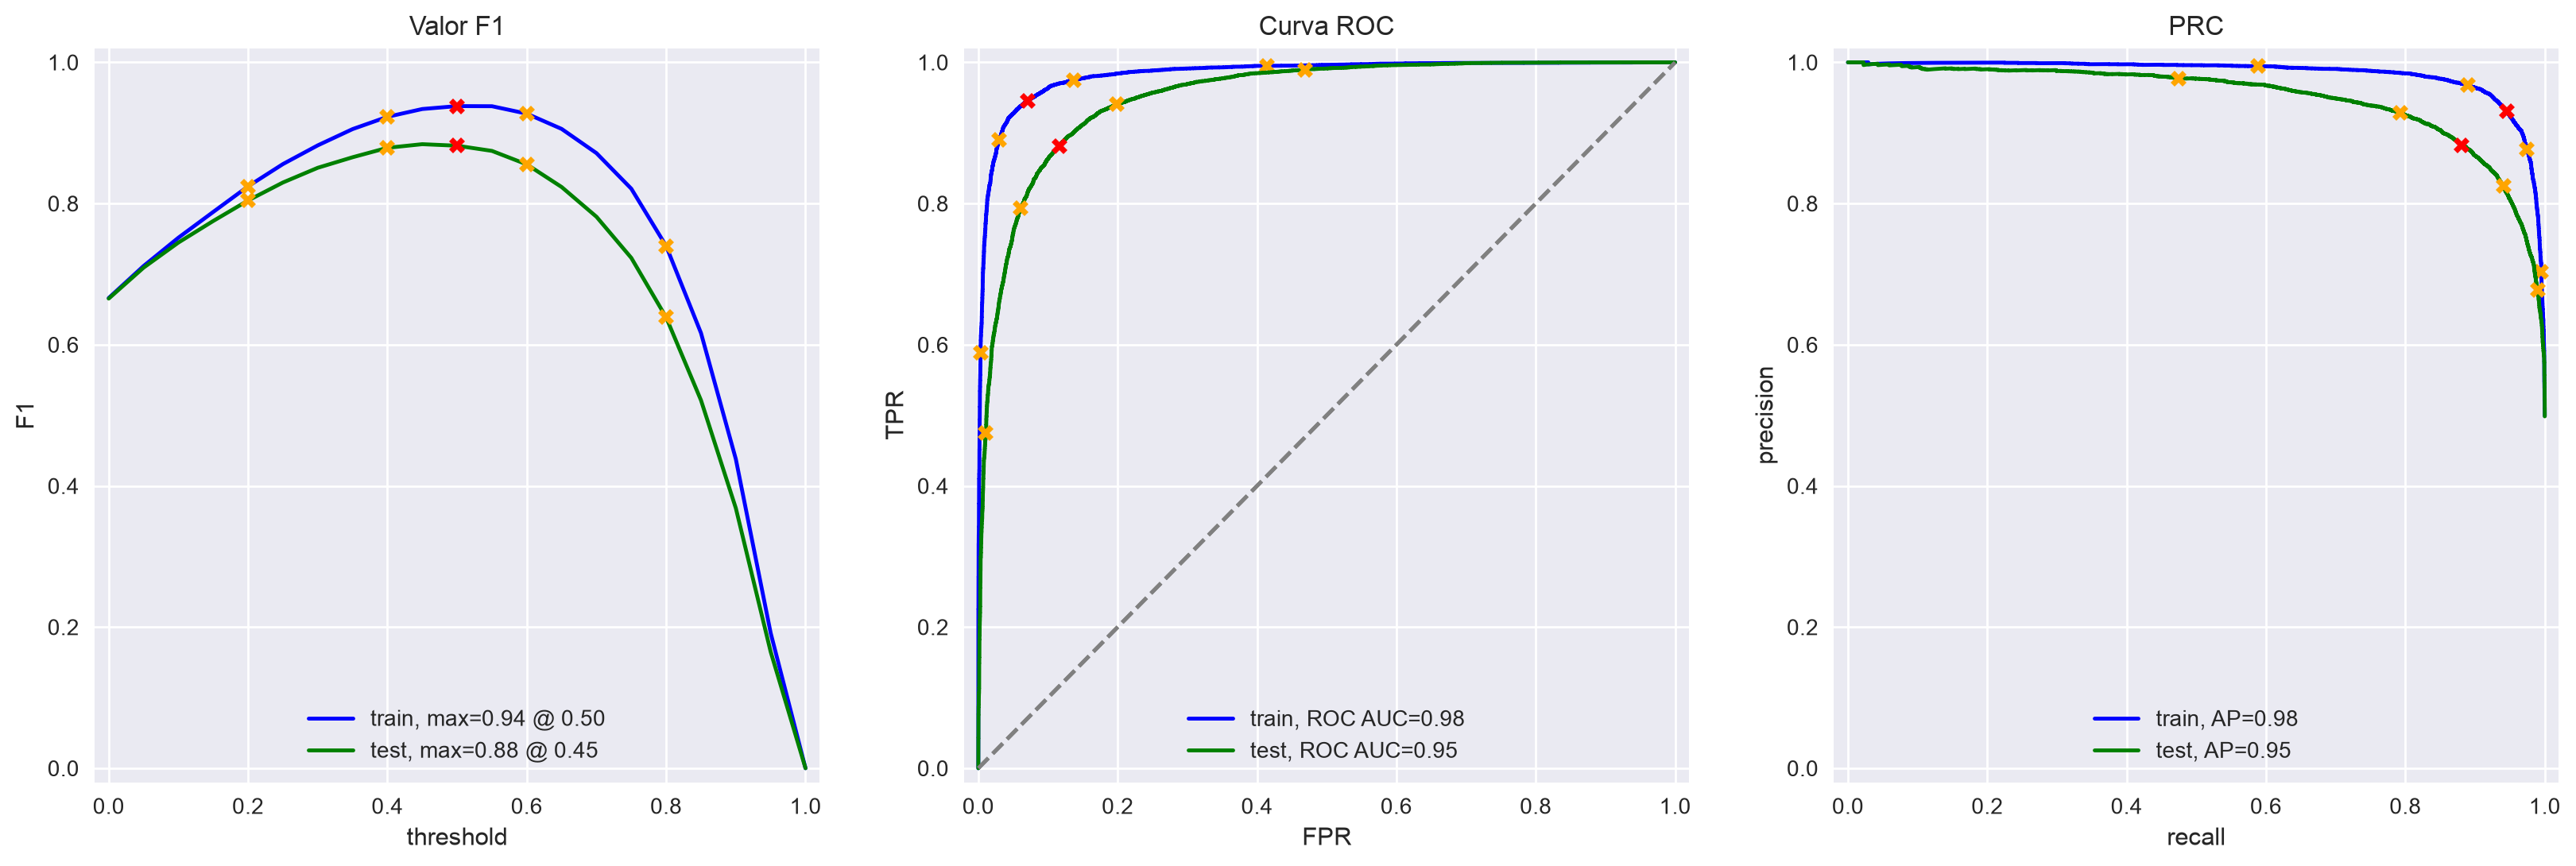

In [76]:
# Evaluación del modelo
evaluate_model(model_2, train_features_2, train_target, test_features_2, test_target)

**Valor F1:**

La gráfica muestra cómo varía la métrica F1 conforme cambia el umbral de decisión del clasificador. Se observa que el mejor desempeño en entrenamiento se obtiene con un F1 de 0.94 utilizando un umbral de 0.50, mientras que en el conjunto de prueba el máximo F1 es de 0.88 con un umbral de 0.45.

La diferencia entre ambos conjuntos es relativamente pequeña, lo que indica que el modelo mantiene una buena capacidad de generalización. 

**Curva ROC:**

La curva ROC compara la tasa de verdaderos positivos (TPR) frente a la tasa de falsos positivos (FPR). En este caso, ambas curvas se encuentran muy próximas a la esquina superior izquierda, indicando un excelente poder de discriminación.

Los valores del área bajo la curva (ROC AUC) son:

* Entrenamiento: 0.98
* Prueba: 0.95

Estos resultados muestran que el modelo distingue correctamente entre ambas clases en la gran mayoría de los casos.

**Curva PR:**

La curva Precision-Recall muestra el compromiso entre precisión y recall, siendo especialmente útil cuando existen clases desbalanceadas.

En este caso, tanto la precisión como el recall permanecen elevados durante gran parte de la curva. El Average Precision (AP) obtenido es:

* Entrenamiento: 0.98
* Prueba: 0.95

Solo cuando el recall se aproxima al 100% se observa una disminución de la precisión, un comportamiento esperado al intentar recuperar prácticamente todos los ejemplos positivos.


**Conclusión general del modelo:**

En conjunto, las tres métricas muestran un desempeño sólido del modelo. El mejor equilibrio entre precisión y recall se alcanza con un umbral cercano a 0.45–0.50, donde el F1 obtiene su valor máximo. Asimismo, los valores de ROC AUC (0.95) y Average Precision (0.95) en el conjunto de prueba evidencian una excelente capacidad de discriminación y una buena generalización. La diferencia reducida entre los resultados de entrenamiento y prueba sugiere que el modelo no presenta un sobreajuste significativo y es adecuado para realizar predicciones sobre nuevos datos.

### Modelo 3 - spaCy, TF-IDF y LR

In [77]:
import os
import spacy
import joblib

# Cargar el modelo deshabilitando los componenetes pesados que no usaremos
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

In [78]:
def text_preprocessing_3(text):

    doc = nlp(text)
    #tokens = [token.lemma_ for token in doc if not token.is_stop]
    tokens = [token.lemma_ for token in doc]

    return ' '.join(tokens)

# Función optimizada para procesar un solo documento (ya analizado por spaCy)
def extract_lemmas(doc):
    return ' '.join([token.lemma_ for token in doc])

In [ ]:
CACHE_LISTS = "corpus_lemanticized.joblib"
FORCE_GENERATION = False

if os.path.exists(CACHE_LISTS) and not FORCE_GENERATION:
    print("Cargando listas lematizadas...")
    train_corpus_lemm, test_corpus_lemm = joblib.load(CACHE_LISTS)
    print("Listas cargadas.")

else:
    print("Procesando texto con spaCy...")
    docs_train = nlp.pipe(df_reviews_train["review"], batch_size=100)
    docs_test = nlp.pipe(df_reviews_test["review"], batch_size=100)

    train_corpus_lemm = [extract_lemmas(doc) for doc in docs_train]
    test_corpus_lemm = [extract_lemmas(doc) for doc in docs_test]

    # Guardar las dos listas juntas en un archivo comprimido
    joblib.dump((train_corpus_lemm, test_corpus_lemm), CACHE_LISTS, compress=3)
    print(f"Listas guardadas en {CACHE_LISTS}.")

Cargando listas lematizadas...
Listas cargadas.


In [80]:
# crear un contador y definir las palabras vacías
tfidf_vectorizer_3 = TfidfVectorizer(stop_words=stop_words)

# calcular el TF-IDF para las features de entrenamiento lemantizados
train_features_3 = tfidf_vectorizer_3.fit_transform(train_corpus_lemm)

# calcular el TF-IDF para las features de prueba lemantizadas
test_features_3 = tfidf_vectorizer_3.transform(test_corpus_lemm)

In [81]:
# Incialización y entrenamiento del modelo
model_3 = LogisticRegression().fit(train_features_3, train_target)

          train  test
Accuracy   0.93  0.88
F1         0.93  0.88
APS        0.98  0.95
ROC AUC    0.98  0.95


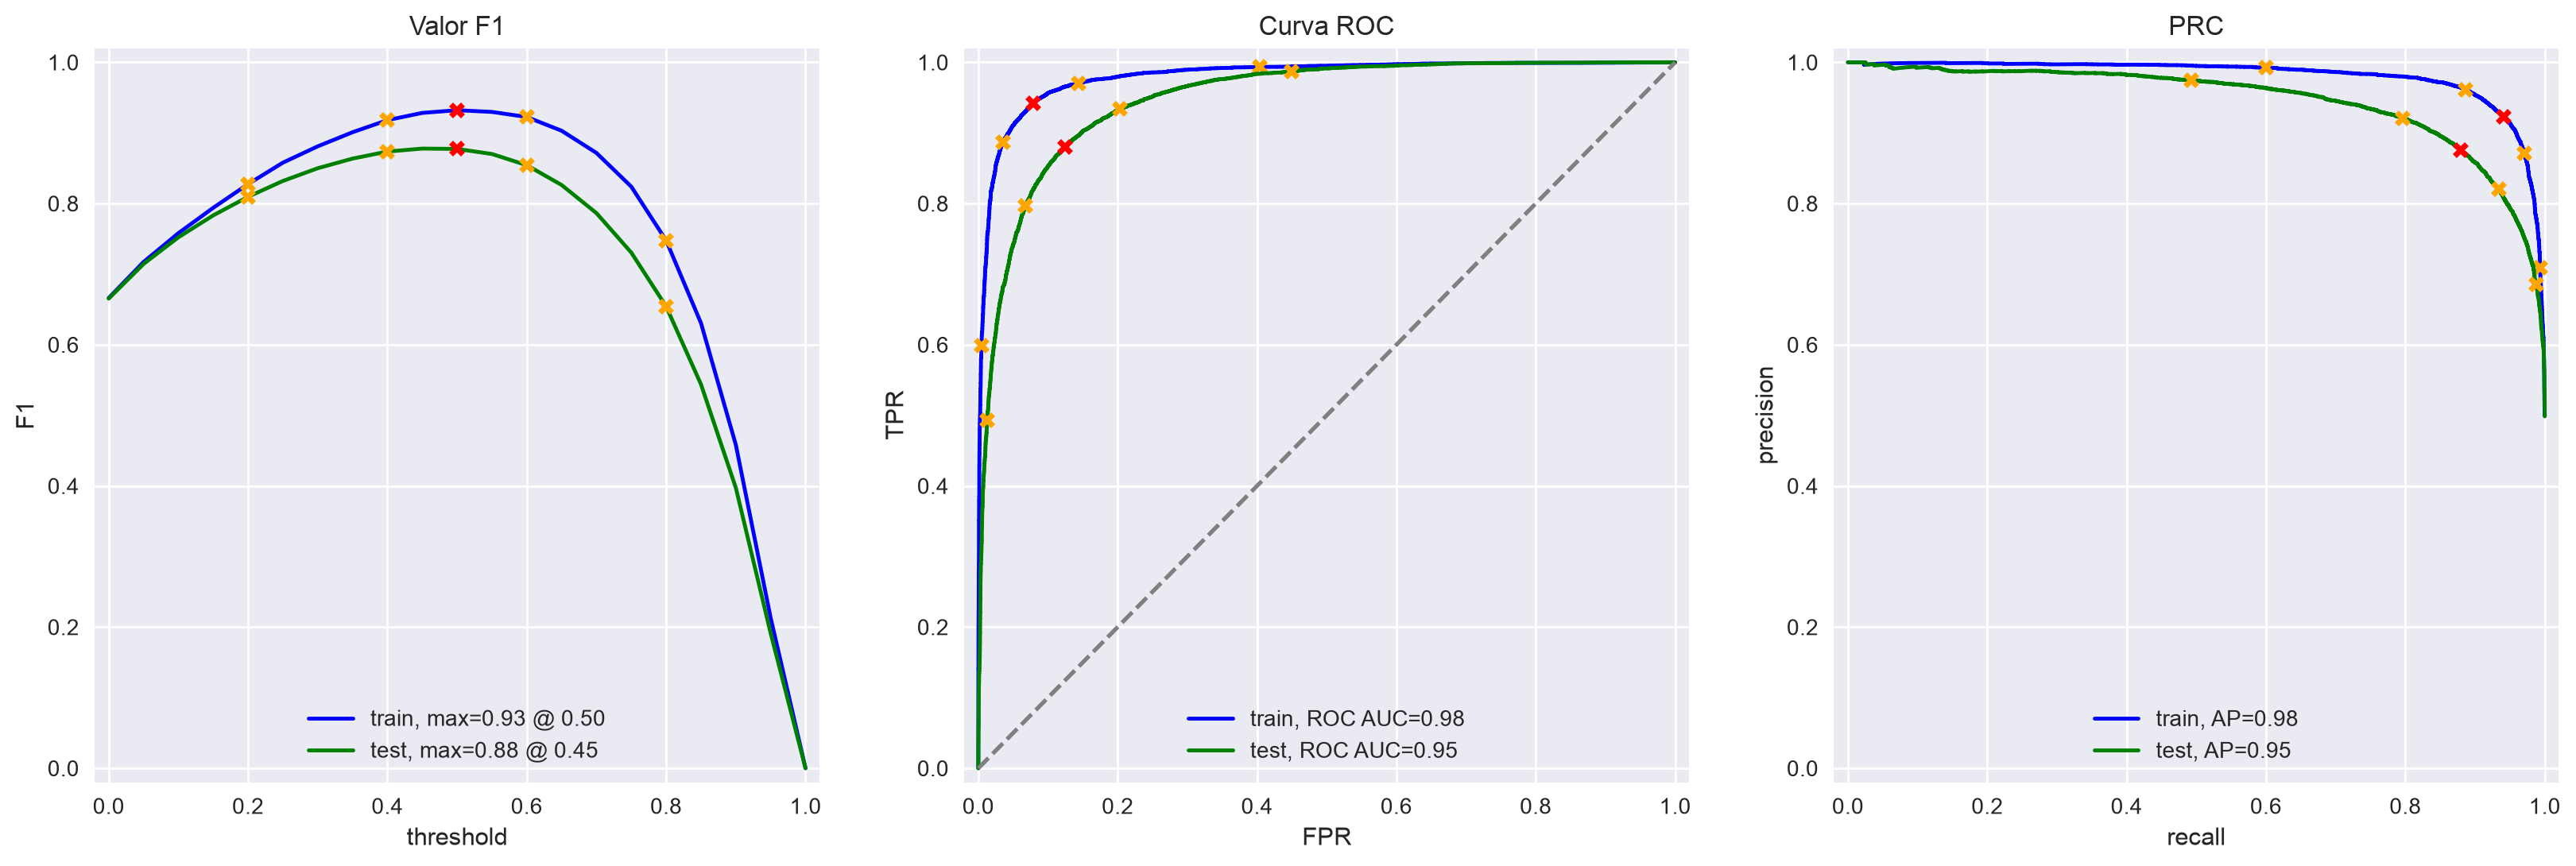

In [82]:
# Evaluación del modelo
evaluate_model(model_3, train_features_3, train_target, test_features_3, test_target)

**Valor F1:**

Se observa que el mejor desempeño en entrenamiento se obtiene con un F1 de 0.93 utilizando un umbral de 0.50, mientras que en el conjunto de prueba el máximo F1 es de 0.88 con un umbral de 0.45.

La diferencia entre ambos conjuntos es relativamente pequeña, lo que indica que el modelo mantiene una buena capacidad de generalización. 

**Curva ROC:**

En este caso, ambas curvas se encuentran muy próximas a la esquina superior izquierda, indicando un excelente poder de discriminación.

Los valores del área bajo la curva (ROC AUC) son:

* Entrenamiento: 0.98
* Prueba: 0.95

Estos resultados muestran que el modelo distingue correctamente entre ambas clases en la gran mayoría de los casos.

**Curva PR:**

En este caso, tanto la precisión como el recall permanecen elevados durante gran parte de la curva. El Average Precision (AP) obtenido es:

* Entrenamiento: 0.98
* Prueba: 0.95

Solo cuando el recall se aproxima al 100% se observa una disminución de la precisión, un comportamiento esperado al intentar recuperar prácticamente todos los ejemplos positivos.


**Conclusión general del modelo:**

El modelo tiene un buen desempeño, comparandolo con el anterior en el que la diferencia fue que en este modelo se incluyo la lemantización, la única diferencia en cuando al score fue en la metrica f1 del conjunto de entrenamiento, reduciendose en 0.01 en comparación con el anterior modelo en el que no se incluia la lemantización.

### Modelo 4 - spaCy, TF-IDF y LGBMClassifier

In [83]:
from lightgbm import LGBMClassifier

* train_features_3: features para el conjunto de entrenamiento transformado previamente (TF-IDF).
* train_target: objetivo del conjunto de entrenamiento, positivo 1, negativo 0.
* test_features_3: features del conjunto de prueba transformado previamente (TF-IDF).
* test_target: objetivo del conjunto de prueba, positivo 1, negativo 0.

In [84]:
model_4 = LGBMClassifier()     

model_4.fit(train_features_3, train_target)

[LightGBM] [Info] Number of positive: 11884, number of negative: 11912
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.547672 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 461176
[LightGBM] [Info] Number of data points in the train set: 23796, number of used features: 9592
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499412 -> initscore=-0.002353
[LightGBM] [Info] Start training from score -0.002353


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


          train  test
Accuracy   0.91  0.86
F1         0.92  0.86
APS        0.97  0.93
ROC AUC    0.97  0.94


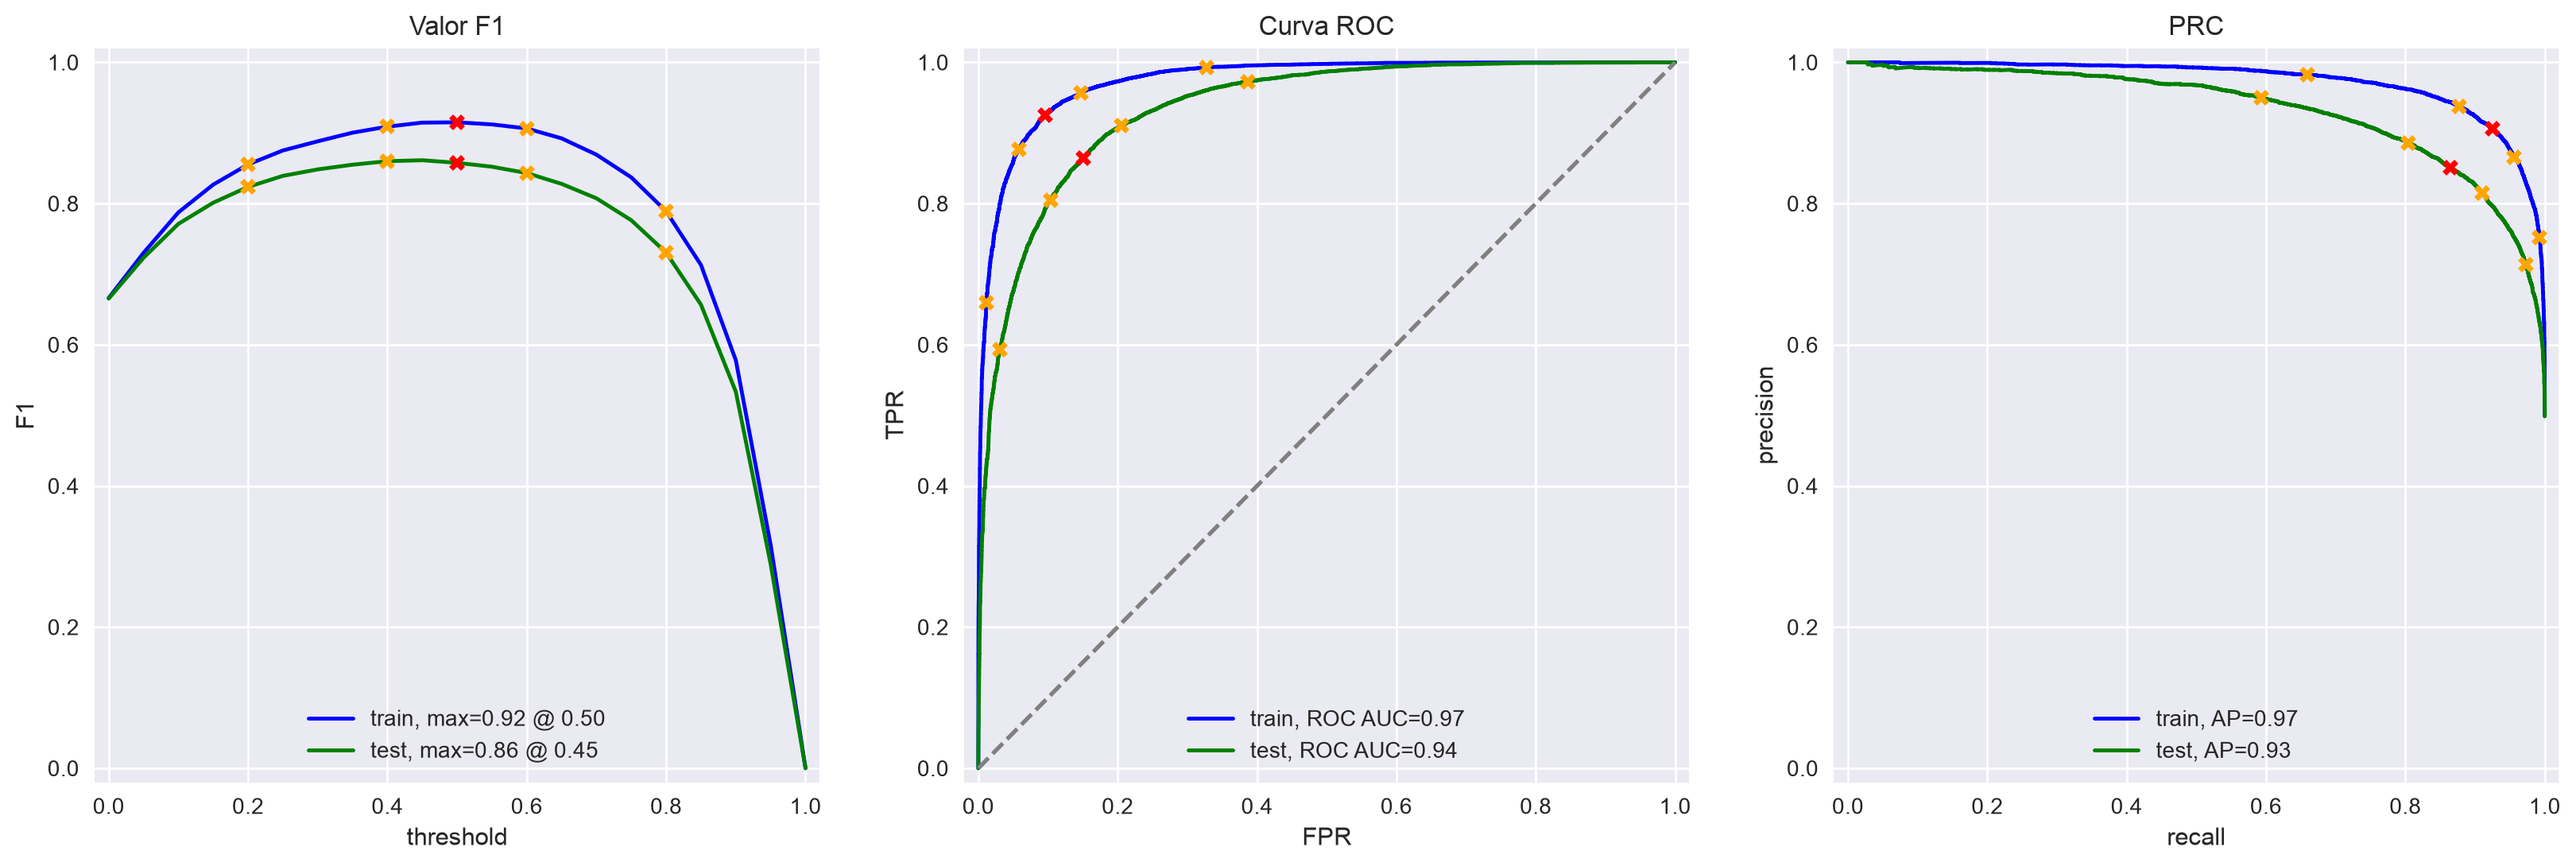

In [85]:
# Evaluación del modelo
evaluate_model(model_4, train_features_3, train_target, test_features_3, test_target)

**Valor F1:**

Se observa que el mejor desempeño en entrenamiento se obtiene con un F1 de 0.92 utilizando un umbral de 0.50, mientras que en el conjunto de prueba el máximo F1 es de 0.86 con un umbral de 0.45.

La diferencia entre ambos conjuntos es relativamente pequeña, lo que indica que el modelo mantiene una buena capacidad de generalización. 

**Curva ROC:**

En este caso, ambas curvas se encuentran muy próximas a la esquina superior izquierda, indicando un excelente poder de discriminación.

Los valores del área bajo la curva (ROC AUC) son:

* Entrenamiento: 0.97
* Prueba: 0.94

Estos resultados muestran que el modelo distingue correctamente entre ambas clases en la gran mayoría de los casos.

**Curva PR:**

En este caso, tanto la precisión como el recall permanecen elevados durante gran parte de la curva. El Average Precision (AP) obtenido es:

* Entrenamiento: 0.97
* Prueba: 0.93


**Conclusión general del modelo:**

El modelo fue entreno con un conjunto lamantizado y transformado (TF-IDF). Comparandolo con los anteriores modelos este ha tomado mucho más tiempo que los anteriores pero las métricas no han mejorado. En general el modelo aun así tiene un buen desempeño.

###  Modelo 9 - BERT

In [86]:
import os
import torch
import transformers

In [87]:
tokenizer = transformers.BertTokenizer.from_pretrained('bert-base-uncased')
config = transformers.BertConfig.from_pretrained('bert-base-uncased')
model = transformers.BertModel.from_pretrained('bert-base-uncased')

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7835.26it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [88]:
corpus_train_9 = df_reviews_train['review_norm'][:3000]
corpus_test_9 = df_reviews_test['review_norm'][:3000]
train_target_9 = train_target[:3000]
test_target_9 = test_target[:3000]

In [89]:
def BERT_text_to_embeddings(texts, max_length=512, batch_size=100, force_device=None, disable_progress_bar=False):

    ids_list = []
    attention_mask_list = []

    # texto al id de relleno de tokens junto con sus máscaras de atención

    for input_text in texts:
        ids = tokenizer.encode(input_text.lower(), add_special_tokens=True, truncation=True, max_length=max_length)
        padded = np.array(ids + [0]*(max_length - len(ids)))
        attention_mask = np.where(padded != 0, 1, 0)
        ids_list.append(padded)
        attention_mask_list.append(attention_mask)

    if force_device is not None:
        device = torch.device(force_device)
    else:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    # device = torch.device('mps')
    model.to(device)
    if not disable_progress_bar:
        print(f'Uso del dispositivo {device}.')

    # obtener insertados en lotes

    embeddings = []

    for i in tqdm(range(math.ceil(len(ids_list)/batch_size)), disable=disable_progress_bar):

        ids_batch = torch.LongTensor(np.array(ids_list[batch_size*i:batch_size*(i+1)])).to(device)
        attention_mask_batch = torch.LongTensor(np.array(attention_mask_list[batch_size*i:batch_size*(i+1)])).to(device)

        with torch.no_grad():
            model.eval()
            batch_embeddings = model(input_ids=ids_batch, attention_mask=attention_mask_batch)
        embeddings.append(batch_embeddings[0][:,0,:].detach().cpu().numpy())

    return np.concatenate(embeddings)

In [90]:
PATH_BERT_FEATURES = 'features_9.npz'
FORCE_GENERATION_9 = False 

if os.path.exists(PATH_BERT_FEATURES) and not FORCE_GENERATION_9:
    print(f"El archivo '{PATH_BERT_FEATURES}' ya existe. Cargando embeddings de BERT...")
    
    # Cargar los NDArrays guardados
    with np.load(PATH_BERT_FEATURES) as data:
        train_features_9 = data['train_features_9']
        test_features_9 = data['test_features_9']
        
    print(f"Embeddings cargados exitosamente.")
    print(f"   - Forma train: {train_features_9.shape}")
    print(f"   - Forma test: {test_features_9.shape}")

else:
    if FORCE_GENERATION_9:
        print(f"Forzando generación. Extrayendo embeddings con BERT nuevamente...")
    else:
        print(f"⚠️ El archivo '{PATH_BERT_FEATURES}' no existe. Generando embeddings con BERT...")

    # ¡Atención! La ejecución de BERT para miles de textos puede llevar mucho tiempo en la CPU, al menos varias horas
    train_features_9 = BERT_text_to_embeddings(corpus_train_9)
    test_features_9 = BERT_text_to_embeddings(corpus_test_9)

    # Guardar ambos arreglos comprimidos en el mismo archivo .npz
    np.savez_compressed(
        PATH_BERT_FEATURES, 
        train_features_9=train_features_9, 
        test_features_9=test_features_9
    )
    print(f"¡Embeddings guardados exitosamente en '{PATH_BERT_FEATURES}'!")

El archivo 'features_9.npz' ya existe. Cargando embeddings de BERT...
Embeddings cargados exitosamente.
   - Forma train: (3000, 768)
   - Forma test: (3000, 768)


In [91]:
print(df_reviews_train['review_norm'].shape)
print(train_features_9.shape)
print(train_target_9.shape)

(23796,)
(3000, 768)
(3000,)


In [92]:
print(df_reviews_test['review_norm'].shape)
print(test_features_9.shape)
print(test_target_9.shape)

(23535,)
(3000, 768)
(3000,)


In [93]:
model_9 = LogisticRegression()
model_9.fit(train_features_9, train_target_9)

/Users/felicianorodriguez/anaconda3/envs/nlp_environment/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

          train  test
Accuracy   0.93  0.84
F1         0.93  0.84
APS        0.98  0.92
ROC AUC    0.98  0.91


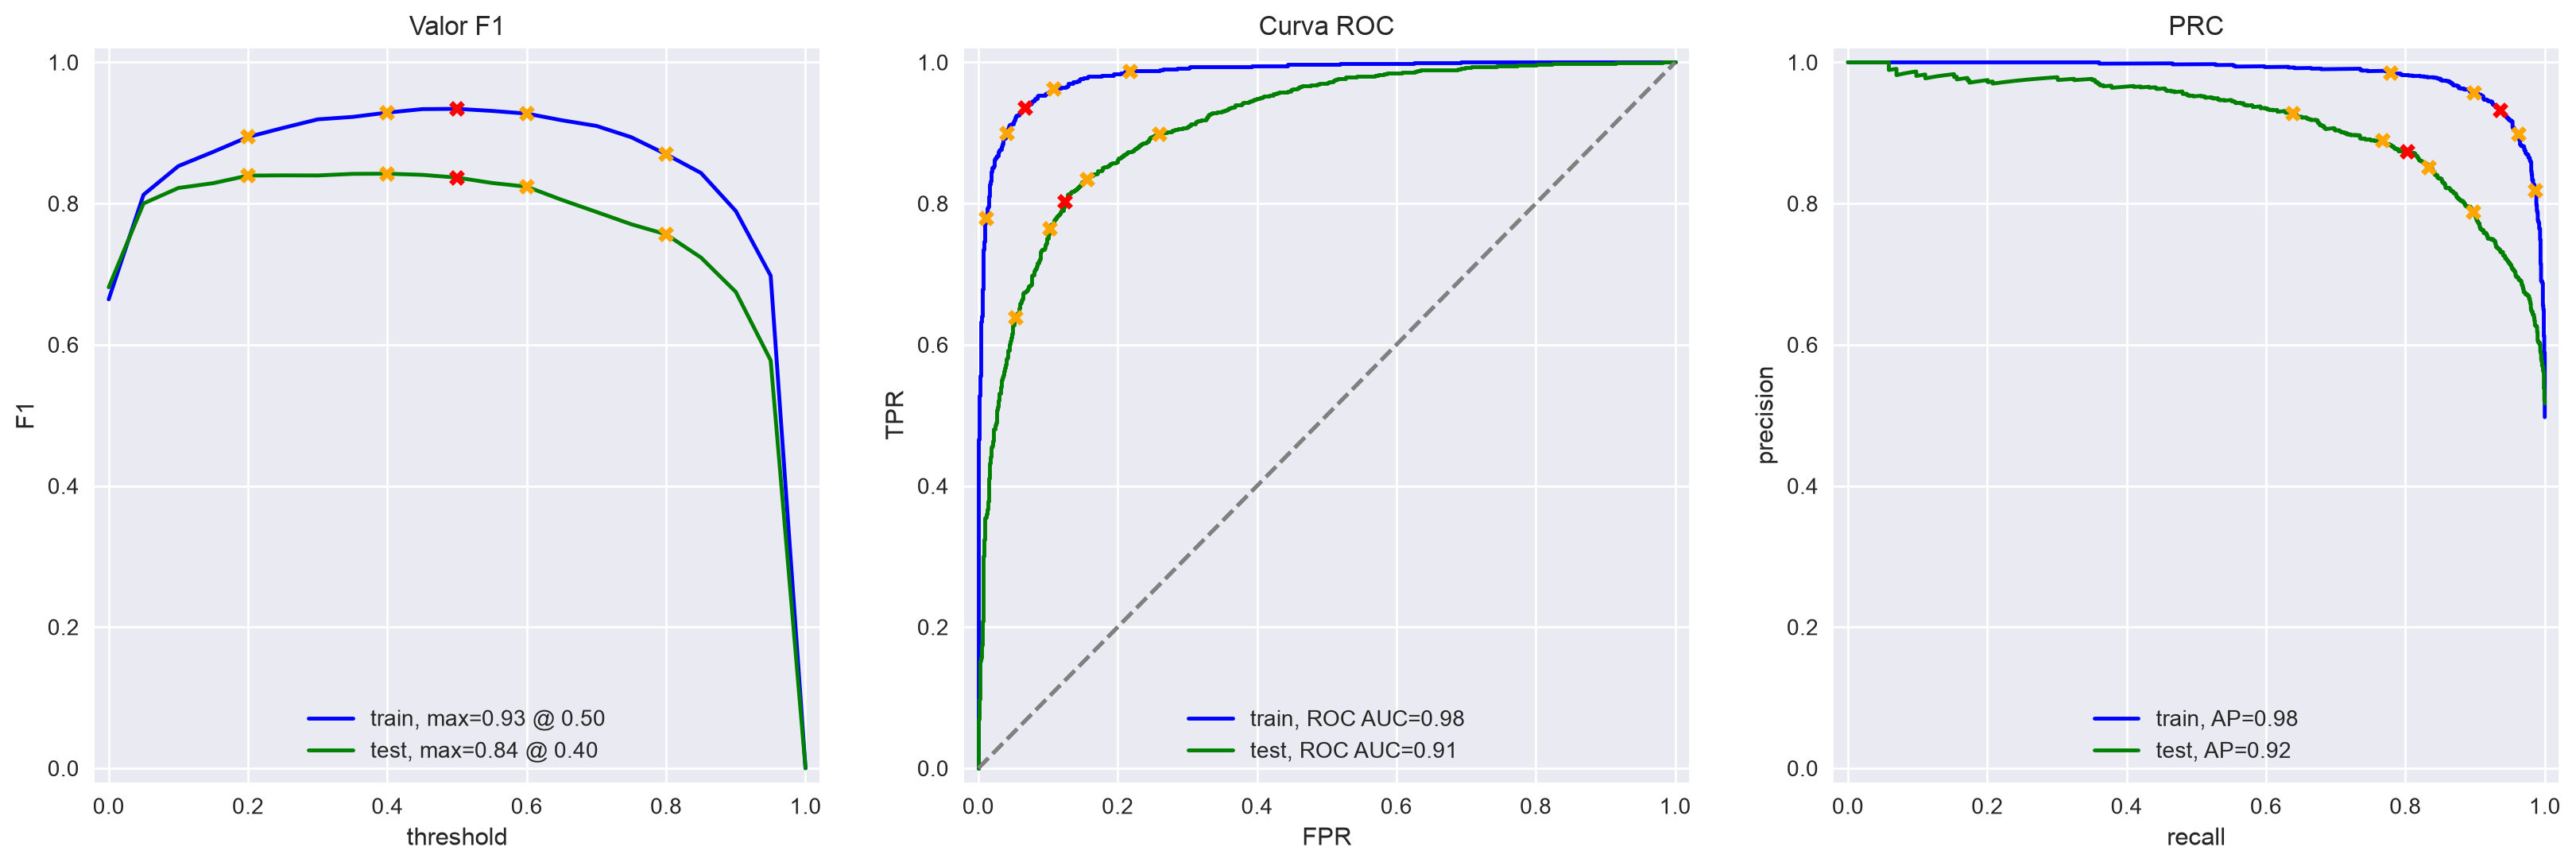

In [94]:
# Evaluación del modelo
evaluate_model(model_9, train_features_9, train_target_9, test_features_9, test_target_9)

Se proceso únicamente 3000 reseñas con BERT para entrenar el modelo. La regresión Logistica fue entrenado con 3000 reseñas.

**Valor F1:**

Se observa que el mejor desempeño en entrenamiento se obtiene con un F1 de 0.93 utilizando un umbral de 0.50, mientras que en el conjunto de prueba el máximo F1 es de 0.84 con un umbral de 0.40.

La diferencia entre ambos conjuntos es medianamente grande, tenemos una diferencia casi de 10 puntos.

**Curva ROC:**

En este caso, ambas curvas se encuentran muy próximas a la esquina superior izquierda, indicando un excelente poder de discriminación.

Los valores del área bajo la curva (ROC AUC) son:

* Entrenamiento: 0.98
* Prueba: 0.91

Existe una diferencia una diferencia medianamente grande entre las métricas de los conjuntos, pero se acercan mucho a la izquina superior izquierda, el modelo discrima las clases bien.

**Curva PR:**

En este caso, tanto la precisión como el recall permanecen elevados durante gran parte de la curva. El Average Precision (AP) obtenido es:

* Entrenamiento: 0.98
* Prueba: 0.92


**Conclusión general del modelo:**

El modelo fue entrenado con 3000 reseñas, hay una pequeña diferencia entre las metricas del conjunto de entrenamiento y el conjunto de prueba, quiza esta métrica podría mejorarse al utilizar las 33 mil reseñas. En general el modelo funciona muy bien tomando en cuenta que fue entrenado con 3000 reseñas.

## Mis reseñas

In [95]:
# puedes eliminar por completo estas reseñas y probar tus modelos en tus propias reseñas; las que se muestran a continuación son solo ejemplos

my_reviews = pd.DataFrame([
    'I did not simply like it, not my kind of movie.',
    'Well, I was bored and felt asleep in the middle of the movie.',
    'I was really fascinated with the movie',
    'Even the actors looked really old and disinterested, and they got paid to be in the movie. What a soulless cash grab.',
    'I didn\'t expect the reboot to be so good! Writers really cared about the source material',
    'The movie had its upsides and downsides, but I feel like overall it\'s a decent flick. I could see myself going to see it again.',
    'What a rotten attempt at a comedy. Not a single joke lands, everyone acts annoying and loud, even kids won\'t like this!',
    'Launching on Netflix was a brave move & I really appreciate being able to binge on episode after episode, of this exciting intelligent new drama.'
], columns=['review'])

"""
my_reviews = pd.DataFrame([
    'Simplemente no me gustó, no es mi tipo de película.',
    'Bueno, estaba aburrido y me quedé dormido a media película.',
    'Estaba realmente fascinada con la película',
    'Hasta los actores parecían muy viejos y desinteresados, y les pagaron por estar en la película. Qué robo tan desalmado.',
    '¡No esperaba que el relanzamiento fuera tan bueno! Los escritores realmente se preocuparon por el material original',
    'La película tuvo sus altibajos, pero siento que, en general, es una película decente. Sí la volvería a ver',
    'Qué pésimo intento de comedia. Ni una sola broma tiene sentido, todos actúan de forma irritante y ruidosa, ¡ni siquiera a los niños les gustará esto!',
    'Fue muy valiente el lanzamiento en Netflix y realmente aprecio poder seguir viendo episodio tras episodio de este nuevo drama tan emocionante e inteligente.'
], columns=['review'])
"""

my_reviews['review_norm'] = my_reviews['review'].apply(normalize_reviews)

my_reviews

,review,review_norm
0,"I did not simply like it, not my kind of movie.",I did not simply like it not my kind of movie
1,"Well, I was bored and felt asleep in the middl...",Well I was bored and felt asleep in the middle...
2,I was really fascinated with the movie,I was really fascinated with the movie
3,Even the actors looked really old and disinter...,Even the actors looked really old and disinter...
4,I didn't expect the reboot to be so good! Writ...,I didn t expect the reboot to be so good Write...
5,"The movie had its upsides and downsides, but I...",The movie had its upsides and downsides but I ...
6,What a rotten attempt at a comedy. Not a singl...,What a rotten attempt at a comedy Not a single...
7,Launching on Netflix was a brave move & I real...,Launching on Netflix was a brave move I really...


### Modelo 2

In [96]:
texts = my_reviews['review_norm']

my_reviews_pred_prob = model_2.predict_proba(tfidf_vectorizer_2.transform(texts))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.14:  I did not simply like it not my kind of movie
0.15:  Well I was bored and felt asleep in the middle of the movie
0.53:  I was really fascinated with the movie
0.11:  Even the actors looked really old and disinterested and they got paid to be in the movie What a soul
0.30:  I didn t expect the reboot to be so good Writers really cared about the source material
0.47:  The movie had its upsides and downsides but I feel like overall it s a decent flick I could see myse
0.04:  What a rotten attempt at a comedy Not a single joke lands everyone acts annoying and loud even kids 
0.82:  Launching on Netflix was a brave move I really appreciate being able to binge on episode after episo


### Modelo 3

In [97]:
texts = my_reviews['review_norm']

my_reviews_pred_prob = model_3.predict_proba(tfidf_vectorizer_3.transform(texts.apply(lambda x: text_preprocessing_3(x))))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.20:  I did not simply like it not my kind of movie
0.15:  Well I was bored and felt asleep in the middle of the movie
0.59:  I was really fascinated with the movie
0.13:  Even the actors looked really old and disinterested and they got paid to be in the movie What a soul
0.36:  I didn t expect the reboot to be so good Writers really cared about the source material
0.50:  The movie had its upsides and downsides but I feel like overall it s a decent flick I could see myse
0.04:  What a rotten attempt at a comedy Not a single joke lands everyone acts annoying and loud even kids 
0.92:  Launching on Netflix was a brave move I really appreciate being able to binge on episode after episo


### Modelo 4

In [98]:
texts = my_reviews['review_norm']

tfidf_vectorizer_4 = tfidf_vectorizer_3
my_reviews_pred_prob = model_4.predict_proba(tfidf_vectorizer_4.transform(texts.apply(lambda x: text_preprocessing_3(x))))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.57:  I did not simply like it not my kind of movie
0.45:  Well I was bored and felt asleep in the middle of the movie
0.60:  I was really fascinated with the movie
0.39:  Even the actors looked really old and disinterested and they got paid to be in the movie What a soul
0.69:  I didn t expect the reboot to be so good Writers really cared about the source material
0.72:  The movie had its upsides and downsides but I feel like overall it s a decent flick I could see myse
0.26:  What a rotten attempt at a comedy Not a single joke lands everyone acts annoying and loud even kids 
0.81:  Launching on Netflix was a brave move I really appreciate being able to binge on episode after episo


### Modelo 9

In [99]:
MY_REVIEWS_PATH = 'my_reviews_features_9.npz'
FORCE_GENERATION_MYRE = False 

if os.path.exists(MY_REVIEWS_PATH) and not FORCE_GENERATION_MYRE:
    print(f"El archivo '{MY_REVIEWS_PATH}' ya existe. Cargando embeddings de BERT...")
    
    with np.load(MY_REVIEWS_PATH) as data:
        my_reviews_features_9 = data['my_reviews_features_9']
        
    print(f"cargado exitosamente.")


else:
    if FORCE_GENERATION_MYRE:
        print(f"Forzando..")
    else:
        print(f"El archivo '{MY_REVIEWS_PATH}' no existe.")

    # ¡Atención! La ejecución de BERT para miles de textos puede llevar mucho tiempo en la CPU, al menos varias horas
    my_reviews_features_9 = BERT_text_to_embeddings(my_reviews['review_norm'])

    np.savez_compressed(
        MY_REVIEWS_PATH, 
        my_reviews_features_9=my_reviews_features_9, 
    )
    print(f"Guardado. '{MY_REVIEWS_PATH}'!")

El archivo 'my_reviews_features_9.npz' ya existe. Cargando embeddings de BERT...
cargado exitosamente.


In [100]:
my_reviews_pred_prob = model_9.predict_proba(my_reviews_features_9)[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.38:  I did not simply like it not my kind of movie
0.01:  Well I was bored and felt asleep in the middle of the movie
0.98:  I was really fascinated with the movie
0.00:  Even the actors looked really old and disinterested and they got paid to be in the movie What a soul
0.43:  I didn t expect the reboot to be so good Writers really cared about the source material
0.98:  The movie had its upsides and downsides but I feel like overall it s a decent flick I could see myse
0.00:  What a rotten attempt at a comedy Not a single joke lands everyone acts annoying and loud even kids 
1.00:  Launching on Netflix was a brave move I really appreciate being able to binge on episode after episo


## Conclusiones

**Síntesis del Trabajo:** 

El modelo 1 basado en Regresión Logistica y usando TF-IDF alcanzó un F1 del 88%, superando al baseline en un 03% por lo que es el recomendado para implementarlo en el sistema de Film Junky Union, ya que este modelo liviano tiene un buen desempeño, incluso el preprocesamiento de las reseñas necesita poco procesamiento, comparandolo con otros métodos como BERT.

**Hallazgos Clave:** 

El desarrollar modelo muy complejos no siempre mejoraban las métricas. Incluso a medida que se utilizaban métodos más complejos como BERT o lemantización el preprocesamiento requerían más tiempo y procesamiento, pero nunca mejoraba las métricas.



**Limitaciones y Próximos Pasos:** 

A pesar del alto rendimiento en el modelo (modelo 1 ), análisando en reseñas personalizadas, he podido ver que el usar negaciones contribuye a que el modelo lo tome como una reseña negativa incluso si la reseña es positiva.

Como trabajo futuro, se propone invertigar métodos más complejos para evitar este problema.

# Lista de comprobación

- [x]  Abriste el notebook
- [x]  Cargaste y preprocesaste los datos de texto para su vectorización
- [x]  Transformaste los datos de texto en vectores
- [x]  Entrenaste y probaste los modelos
- [x]  Se alcanzó el umbral de la métrica
- [x]  Colocaste todas las celdas de código en el orden de su ejecución
- [x]  Puedes ejecutar sin errores todas las celdas de código
- [x]  Hay conclusiones

Nota: una disculpa, error mio, no cargue la versión correcta en mi entrega anterior, esta es la correcta. 